# 04 · Which skills are becoming more in demand, and in which occupations?

This notebook uses the clean tables from `02_clean_data.ipynb` and the skill groups from `03_skill_categories.ipynb`. It does not change them.

## How skill demand is measured

- **Vacancy share**: the percentage of vacancies that mention a skill, out of vacancies with at least one skill. This is the main measure. It answers "what share of job ads ask for this skill?".
- Raw counts are **not** used for trends. Vacancies list more skills each year (about 8 in 2015, about 11 in 2025), so raw counts rise for almost every skill.
- **Mention share**: a skill's share of all skill mentions in the year. Because it adds up to 100% each year, it is not inflated by ads listing more skills.
- A skill is **emerging** if both shares grow by at least 50%, and **declining** if both fall by at least a third. Everything else is **stable**.

## Periods compared

- **Early**: 2017–2019. **Recent**: 2023–2025. Three-year windows smooth out noise.
- 2015–2016 are left out of the comparison, because a third of their vacancies have no skills recorded.
- 2020 is left out because of the COVID-19 drop.
- 2026 is incomplete (January–August), so it is only shown on the yearly charts and in a separate January–August check.

You can change these settings in the next cell.

## 0. Settings and loading

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 60)

# Periods to compare.
EARLY_YEARS = [2017, 2018, 2019]
RECENT_YEARS = [2023, 2024, 2025]

# A skill must appear in at least this many vacancies in the early or recent period.
# This avoids large percentage changes for very rare skills.
MIN_VACANCIES = 200
MIN_VACANCIES_DOMAIN = 50  # lower threshold for the smaller occupation domains

# A skill is "emerging" if both its vacancy share and its mention share grow by at
# least this factor, and "declining" if both shrink by at least this factor.
# 1.5 means +50% (emerging) or -33% (declining).
CHANGE_FACTOR = 1.5

# Skills to follow closely (exact ESCO labels). Edit freely.
WATCH_LIST = [
    'Python (computer programming)', 'SQL', 'data analytics', 'data mining',
    'machine learning', 'statistics', 'principles of artificial intelligence',
    'cloud technologies', 'risk management', 'use spreadsheets software',
]

# Support running from either the project root or notebooks/.
project_dir = Path.cwd()
if not (project_dir / 'data' / 'processed').is_dir():
    project_dir = project_dir.parent
processed_dir = project_dir / 'data' / 'processed'
output_dir = project_dir / 'outputs' / '04_skill_trends'
output_dir.mkdir(parents=True, exist_ok=True)

def load_table(name):
    parquet = processed_dir / f'{name}.parquet'
    if parquet.exists():
        return pd.read_parquet(parquet)
    return pd.read_csv(processed_dir / f'{name}.csv.gz')

vacancies = load_table('vacancies')
vacancy_skills = load_table('vacancy_skills')

# Skill groups from notebook 03 (one row per skill). Skill names are unique.
skill_group = load_table('skill_categories').set_index('skill')['group']

# Only complete months, and only vacancies with at least one skill.
vac = vacancies[vacancies['in_complete_period'] & vacancies['has_skills']].copy()
vac['domain_code'] = vac['occupation_code'].astype(str).str[0]

skills = vacancy_skills.merge(vac[['vacancy_key', 'year', 'month', 'domain_code']],
                              on='vacancy_key', how='inner')
skills['skill'] = skills['skill'].astype(str)

print(f'Vacancies with skills (complete months): {len(vac):,}')
print(f'Vacancy–skill rows used:                {len(skills):,}')
print(f'Distinct skills:                         {skills["skill"].nunique():,}')

Vacancies with skills (complete months): 276,463
Vacancy–skill rows used:                2,721,579
Distinct skills:                         4,635


## 1. Base figures per year

These are the denominators. `avg_skills` shows why raw counts can't be compared across years.

In [2]:
base = pd.DataFrame({
    'vacancies_with_skills': vac.groupby('year').size(),
    'skill_mentions': skills.groupby('year').size(),
})
base['avg_skills'] = (base['skill_mentions'] / base['vacancies_with_skills']).round(2)
display(base)

,vacancies_with_skills,skill_mentions,avg_skills
year,,,
2015,13613,106128,7.80
2016,16998,140869,8.29
2017,21956,184672,8.41
2018,24093,216077,8.97
2019,23326,215942,9.26
2020,19885,192881,9.70
2021,28501,286978,10.07
2022,30463,312098,10.25
2023,26195,265670,10.14


## 2. Yearly share for every skill

Each skill appears at most once per vacancy (checked in notebook 02), so counting rows counts vacancies.

In [3]:
counts = skills.groupby(['year', 'skill']).size().rename('vacancies').reset_index()
counts['vacancy_share_pct'] = (counts['vacancies'] /
                               counts['year'].map(base['vacancies_with_skills']) * 100)
counts['mention_share_pct'] = (counts['vacancies'] /
                               counts['year'].map(base['skill_mentions']) * 100)

yearly_share = counts.pivot(index='skill', columns='year', values='vacancy_share_pct').fillna(0)

print('Most common skills in the most recent full year:')
last_full = max(RECENT_YEARS)
display(yearly_share[last_full].sort_values(ascending=False).head(20).round(1))

Most common skills in the most recent full year:


skill
cooperate with professionals        36.9
communication                       36.3
use microsoft office                32.2
English                             29.4
use technical documentation         25.9
work independently                  24.9
work in teams                       24.9
computer technology                 21.5
French                              20.7
German                              17.8
think creatively                    15.8
show professional responsibility    15.8
plan                                15.4
computer science                    14.5
adapt to changing situations        14.2
economics                           13.3
business knowledge                  10.7
adapt to change                     10.3
accounting                          10.0
sales activities                     9.1
Name: 2025, dtype: float64

## 3. Early vs recent: which skills are emerging or declining?

For each skill, compare the two periods:

- `share_change_pp`: change in vacancy share, in percentage points
- `share_ratio`: recent share divided by early share (2 = doubled)
- `mention_ratio`: the same ratio for the mention share

In [4]:
def skill_change(vac_subset, skills_subset, min_vacancies):
    # Compare early and recent periods for one group of vacancies.
    rows = {}
    for label, years in [('early', EARLY_YEARS), ('recent', RECENT_YEARS)]:
        v = vac_subset[vac_subset['year'].isin(years)]
        s = skills_subset[skills_subset['year'].isin(years)]
        n = s.groupby('skill').size()
        rows[f'{label}_vacancies'] = n
        rows[f'{label}_share_pct'] = n / len(v) * 100 if len(v) else np.nan
        rows[f'{label}_mention_pct'] = n / len(s) * 100 if len(s) else np.nan
    out = pd.DataFrame(rows).fillna(0)
    out['early_vacancies'] = out['early_vacancies'].astype(int)
    out['recent_vacancies'] = out['recent_vacancies'].astype(int)

    out = out[(out['early_vacancies'] >= min_vacancies) |
              (out['recent_vacancies'] >= min_vacancies)].copy()

    # Small constant so skills absent in one period don't divide by zero.
    eps = 0.01
    out['share_change_pp'] = out['recent_share_pct'] - out['early_share_pct']
    out['share_ratio'] = (out['recent_share_pct'] + eps) / (out['early_share_pct'] + eps)
    out['mention_ratio'] = (out['recent_mention_pct'] + eps) / (out['early_mention_pct'] + eps)

    out['trend'] = 'Stable'
    up = (out['share_ratio'] >= CHANGE_FACTOR) & (out['mention_ratio'] >= CHANGE_FACTOR)
    down = (out['share_ratio'] <= 1 / CHANGE_FACTOR) & (out['mention_ratio'] <= 1 / CHANGE_FACTOR)
    out.loc[up, 'trend'] = 'Emerging'
    out.loc[down, 'trend'] = 'Declining'

    cols = ['trend', 'early_vacancies', 'recent_vacancies', 'early_share_pct',
            'recent_share_pct', 'share_change_pp', 'share_ratio', 'mention_ratio']
    return out[cols].sort_values('share_change_pp', ascending=False)

change = skill_change(vac, skills, MIN_VACANCIES)

print(f'Skills with at least {MIN_VACANCIES} vacancies in one period: {len(change):,}')
display(change['trend'].value_counts())

Skills with at least 200 vacancies in one period: 524


trend
Stable       390
Emerging     110
Declining     24
Name: count, dtype: int64

In [5]:
show = lambda t: t.round({'early_share_pct': 2, 'recent_share_pct': 2, 'share_change_pp': 2,
                          'share_ratio': 2, 'mention_ratio': 2})

print('Biggest gains in percentage points (skills that spread the most):')
display(show(change[change['trend'] == 'Emerging'].head(20)))

print('Fastest relative growth (sorted by ratio):')
display(show(change[(change['trend'] == 'Emerging')]
             .sort_values('share_ratio', ascending=False).head(20)))

print('Biggest declines:')
display(show(change[change['trend'] == 'Declining']
             .sort_values('share_change_pp').head(20)))

Biggest gains in percentage points (skills that spread the most):


,trend,early_vacancies,recent_vacancies,early_share_pct,recent_share_pct,share_change_pp,share_ratio,mention_ratio
skill,,,,,,,,
cooperate with professionals,Emerging,10368,25535,14.94,31.89,16.94,2.13,1.76
work in an organised manner,Emerging,2867,6649,4.13,8.30,4.17,2.01,1.65
observe confidentiality,Emerging,1745,5307,2.52,6.63,4.11,2.63,2.14
keep company,Emerging,1719,5261,2.48,6.57,4.09,2.64,2.15
promote sustainability,Emerging,703,3823,1.01,4.77,3.76,4.68,3.67
electrical machines,Emerging,1438,4303,2.07,5.37,3.30,2.58,2.10
assertiveness,Emerging,1386,3400,2.00,4.25,2.25,2.12,1.73
apply information security policies,Emerging,243,2010,0.35,2.51,2.16,7.00,4.93
personal development,Emerging,445,2182,0.64,2.72,2.08,4.20,3.21


Fastest relative growth (sorted by ratio):


,trend,early_vacancies,recent_vacancies,early_share_pct,recent_share_pct,share_change_pp,share_ratio,mention_ratio
skill,,,,,,,,
respect confidentiality obligations,Emerging,41,1558,0.06,1.95,1.89,28.30,11.48
C#,Emerging,27,348,0.04,0.43,0.40,9.09,3.51
manage ICT virtualisation environments,Emerging,24,293,0.03,0.37,0.33,8.43,3.17
promote inclusion,Emerging,23,267,0.03,0.33,0.30,7.96,2.99
sporting events,Emerging,56,505,0.08,0.63,0.55,7.06,3.60
apply information security policies,Emerging,243,2010,0.35,2.51,2.16,7.00,4.93
football,Emerging,26,238,0.04,0.30,0.26,6.47,2.65
application process,Emerging,141,987,0.20,1.23,1.03,5.83,3.80
relate empathetically,Emerging,99,660,0.14,0.82,0.68,5.46,3.33


Biggest declines:


,trend,early_vacancies,recent_vacancies,early_share_pct,recent_share_pct,share_change_pp,share_ratio,mention_ratio
skill,,,,,,,,
use spreadsheets software,Declining,18031,5459,25.99,6.82,-19.17,0.26,0.22
use word processing software,Declining,15317,2711,22.08,3.39,-18.69,0.15,0.13
use presentation software,Declining,11997,1223,17.29,1.53,-15.77,0.09,0.08
Microsoft Access,Declining,6265,494,9.03,0.62,-8.41,0.07,0.07
Java (computer programming),Declining,1839,1347,2.65,1.68,-0.97,0.64,0.54
Italian,Declining,1253,942,1.81,1.18,-0.63,0.65,0.56
use markup languages,Declining,921,566,1.33,0.71,-0.62,0.54,0.48
C\+\+,Declining,614,357,0.89,0.45,-0.44,0.51,0.47
use IT tools,Declining,466,243,0.67,0.30,-0.37,0.46,0.45


## 4. Charts

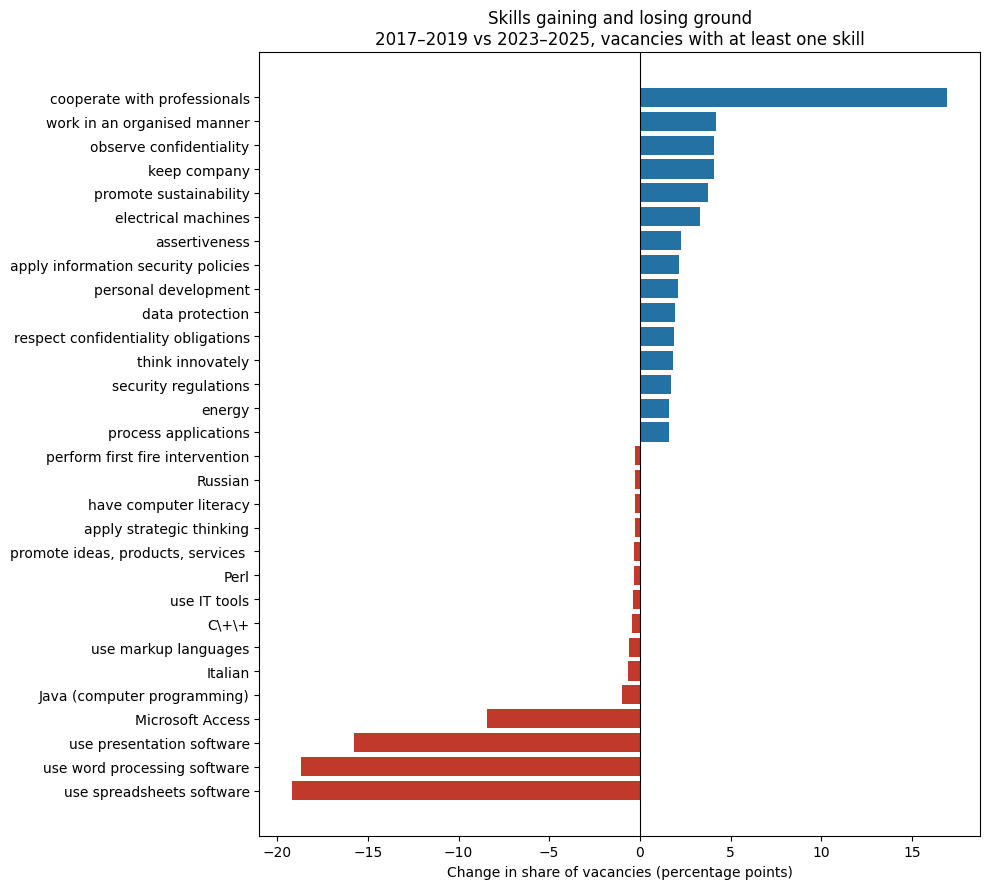

In [6]:
TOP_N = 15
emerging = change[change['trend'] == 'Emerging'].head(TOP_N)
declining = change[change['trend'] == 'Declining'].sort_values('share_change_pp').head(TOP_N)
plot_data = pd.concat([declining, emerging]).sort_values('share_change_pp')

fig, ax = plt.subplots(figsize=(10, 9))
colors = ['#c0392b' if x < 0 else '#2471a3' for x in plot_data['share_change_pp']]
ax.barh(plot_data.index, plot_data['share_change_pp'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Change in share of vacancies (percentage points)')
ax.set_title(f'Skills gaining and losing ground\n'
             f'{EARLY_YEARS[0]}–{EARLY_YEARS[-1]} vs {RECENT_YEARS[0]}–{RECENT_YEARS[-1]}, '
             f'vacancies with at least one skill')
plt.tight_layout()
fig.savefig(output_dir / 'emerging_declining_skills.png', dpi=150)
plt.show()

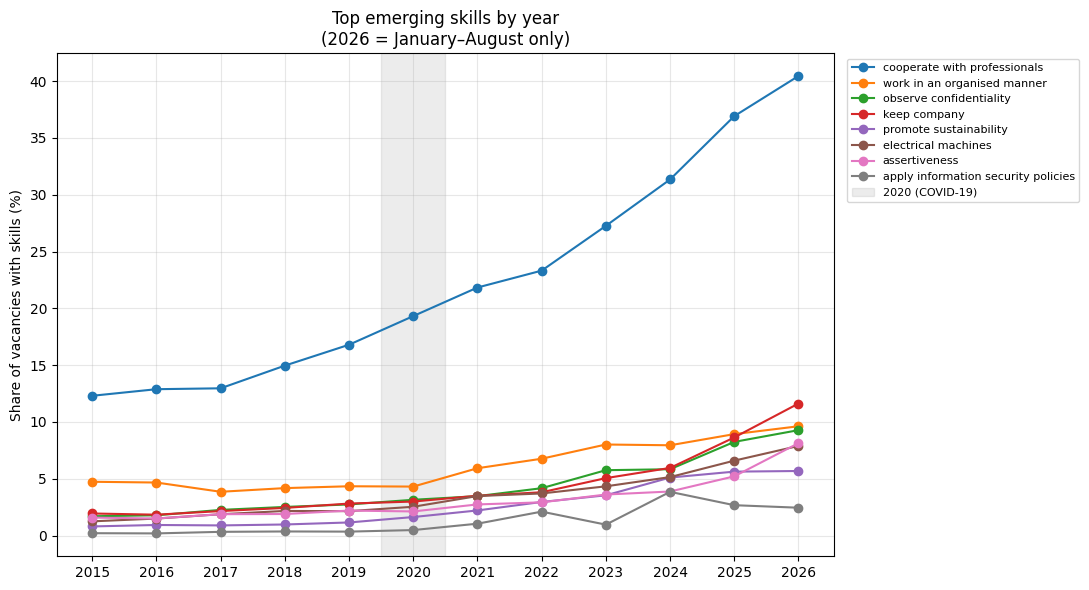

In [7]:
def plot_yearly(skill_list, title, filename):
    fig, ax = plt.subplots(figsize=(11, 6))
    for skill in skill_list:
        if skill in yearly_share.index:
            ax.plot(yearly_share.columns, yearly_share.loc[skill], marker='o', label=skill)
    ax.axvspan(2019.5, 2020.5, color='grey', alpha=0.15, label='2020 (COVID-19)')
    ax.set_ylabel('Share of vacancies with skills (%)')
    ax.set_title(title + '\n(2026 = January–August only)')
    ax.set_xticks(yearly_share.columns)
    ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
    ax.grid(alpha=0.3)
    plt.tight_layout()
    fig.savefig(output_dir / filename, dpi=150)
    plt.show()

plot_yearly(emerging.head(8).index, 'Top emerging skills by year', 'top_emerging_by_year.png')

## 5. Your watch list

Yearly share for the skills in `WATCH_LIST`. Labels that don't exist in the data are reported, so you can fix their spelling.

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
skill,,,,,,,,,,,,
Python (computer programming),0.43,0.72,0.97,1.40,2.39,2.93,3.45,3.05,2.65,3.33,3.29,3.38
SQL,5.36,5.43,5.01,5.36,5.94,6.71,6.31,5.45,3.67,5.21,4.29,3.72
data analytics,0.19,0.35,0.41,0.54,0.77,0.96,1.19,1.22,1.01,1.15,1.11,1.03
data mining,0.39,0.48,0.52,0.42,0.54,0.76,0.79,0.36,0.17,0.77,0.45,0.27
machine learning,0.12,0.23,0.46,0.47,0.97,0.98,1.07,0.98,0.65,1.07,1.35,1.26
statistics,3.61,4.09,3.99,4.41,5.24,5.81,6.30,5.44,4.52,6.81,5.60,5.51
principles of artificial intelligence,0.03,0.02,0.04,0.10,0.12,0.13,0.21,0.29,0.33,0.38,0.67,0.88
cloud technologies,0.51,0.48,0.44,0.49,0.36,0.46,0.61,0.62,0.50,0.72,0.71,0.63
risk management,3.48,2.90,3.00,4.07,3.45,4.16,4.74,4.94,4.55,4.92,4.90,5.66


,trend,early_vacancies,recent_vacancies,early_share_pct,recent_share_pct,share_change_pp,share_ratio,mention_ratio
skill,,,,,,,,
Python (computer programming),Emerging,1110,2477,1.60,3.09,1.49,1.93,1.57
risk management,Stable,2444,3839,3.52,4.79,1.27,1.36,1.12
statistics,Stable,3161,4526,4.56,5.65,1.10,1.24,1.03
data analytics,Stable,400,873,0.58,1.09,0.51,1.88,1.49
machine learning,Stable,443,824,0.64,1.03,0.39,1.60,1.29
principles of artificial intelligence,Emerging,61,370,0.09,0.46,0.37,4.82,2.67
cloud technologies,Stable,298,516,0.43,0.64,0.21,1.49,1.20
data mining,Stable,340,375,0.49,0.47,-0.02,0.96,0.82
SQL,Stable,3777,3518,5.44,4.39,-1.05,0.81,0.67


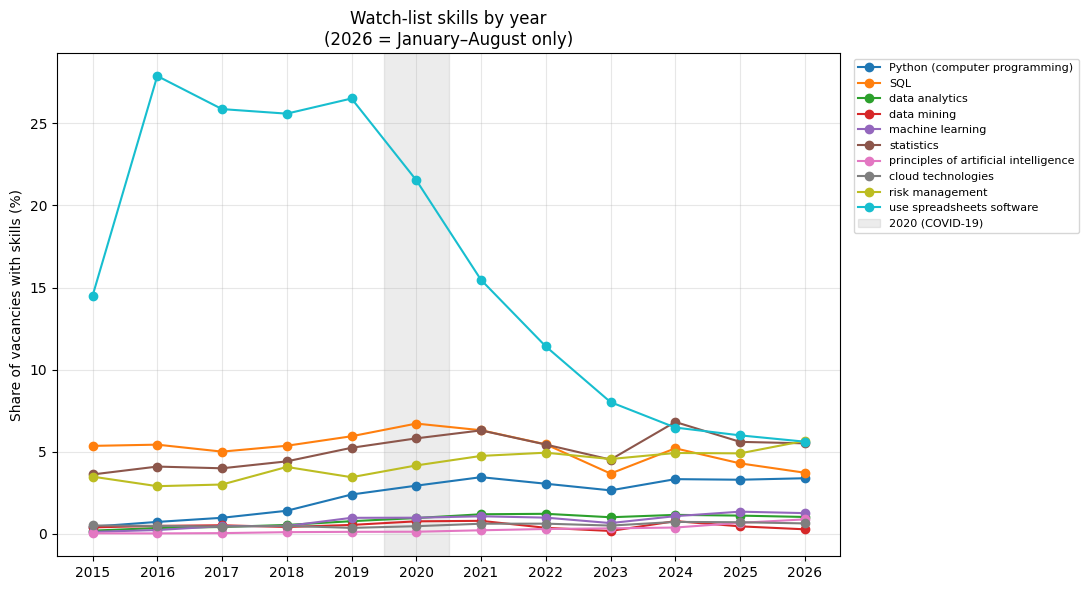

In [8]:
missing_labels = [s for s in WATCH_LIST if s not in yearly_share.index]
if missing_labels:
    print('Not found in the data (check spelling):', missing_labels)
    all_labels = pd.Series(yearly_share.index)
    for label in missing_labels:
        word = label.split()[0].lower()
        print(f'  Similar to "{label}":', list(all_labels[all_labels.str.lower().str.contains(word, regex=False)][:10]))

watch = [s for s in WATCH_LIST if s in yearly_share.index]
display(yearly_share.loc[watch].round(2))

watch_change = skill_change(vac, skills, min_vacancies=0)
display(show(watch_change.loc[watch_change.index.intersection(watch)]))

plot_yearly(watch, 'Watch-list skills by year', 'watch_list_by_year.png')

## 6. In which occupations?

The ROME occupation code starts with a letter for the broad occupation domain (for example `M` = business support, `C` = banking and insurance). The same early-vs-recent comparison is run inside each domain.

In [9]:
DOMAIN_NAMES = {
    'A': 'Agriculture and nature', 'B': 'Arts and crafts',
    'C': 'Banking, insurance and real estate', 'D': 'Retail and sales',
    'E': 'Communication and media', 'F': 'Construction',
    'G': 'Hospitality and tourism', 'H': 'Industry',
    'I': 'Installation and maintenance', 'J': 'Health',
    'K': 'Personal and community services', 'L': 'Performing arts',
    'M': 'Business support (admin, finance, IT, HR)', 'N': 'Transport and logistics',
}

domain_size = pd.DataFrame({
    'early_vacancies': vac[vac['year'].isin(EARLY_YEARS)].groupby('domain_code').size(),
    'recent_vacancies': vac[vac['year'].isin(RECENT_YEARS)].groupby('domain_code').size(),
}).fillna(0).astype(int)
domain_size['domain'] = domain_size.index.map(DOMAIN_NAMES)
domain_size['change_pct'] = ((domain_size['recent_vacancies'] / domain_size['early_vacancies'] - 1)
                             * 100).round(1)
print('Vacancies with skills by domain:')
display(domain_size.sort_values('recent_vacancies', ascending=False))

Vacancies with skills by domain:


,early_vacancies,recent_vacancies,domain,change_pct
domain_code,,,,
M,24637,27303,"Business support (admin, finance, IT, HR)",10.8
K,8466,10616,Personal and community services,25.4
G,6976,7600,Hospitality and tourism,8.9
C,6668,6918,"Banking, insurance and real estate",3.7
F,4804,5925,Construction,23.3
D,4612,4874,Retail and sales,5.7
I,2965,4320,Installation and maintenance,45.7
H,2935,3946,Industry,34.4
N,3047,3087,Transport and logistics,1.3


In [10]:
TOP_PER_DOMAIN = 5
domain_results = []
for code_letter, name in DOMAIN_NAMES.items():
    v = vac[vac['domain_code'] == code_letter]
    if v['year'].isin(EARLY_YEARS).sum() < 300 or v['year'].isin(RECENT_YEARS).sum() < 300:
        continue  # too few vacancies for a reliable comparison
    s = skills[skills['domain_code'] == code_letter]
    res = skill_change(v, s, MIN_VACANCIES_DOMAIN)
    res.insert(0, 'domain', name)
    domain_results.append(res)

domain_change = pd.concat(domain_results).reset_index(names='skill')

top_domain = (domain_change[domain_change['trend'] == 'Emerging']
              .sort_values(['domain', 'share_change_pp'], ascending=[True, False])
              .groupby('domain').head(TOP_PER_DOMAIN))
print(f'Top {TOP_PER_DOMAIN} emerging skills in each domain:')
display(show(top_domain[['domain', 'skill', 'early_share_pct', 'recent_share_pct',
                         'share_change_pp', 'share_ratio']]))

Top 5 emerging skills in each domain:


,domain,skill,early_share_pct,recent_share_pct,share_change_pp,share_ratio
0,Agriculture and nature,adapt to changing situations,2.27,7.30,5.03,3.21
1,Agriculture and nature,perform weed control operations,1.62,6.11,4.49,3.76
2,Agriculture and nature,cooperate with professionals,2.27,6.75,4.48,2.97
5,Agriculture and nature,lead a team,2.92,6.83,3.91,2.34
6,Agriculture and nature,use microsoft office,2.81,6.67,3.86,2.37
22,"Banking, insurance and real estate",cooperate with professionals,22.11,43.02,20.91,1.95
24,"Banking, insurance and real estate",promote sustainability,1.81,9.81,8.00,5.38
27,"Banking, insurance and real estate",personal development,0.93,7.57,6.64,8.07
29,"Banking, insurance and real estate",observe confidentiality,2.31,8.54,6.23,3.69
30,"Banking, insurance and real estate",think creatively,6.21,11.52,5.31,1.85


Generic skills such as "cooperate with professionals" grow almost everywhere, so they dominate the table above. The next table keeps only skills that grow **much faster in a domain than overall** (`vs_overall` = domain ratio divided by overall ratio, at least `CHANGE_FACTOR`). These show how each type of job is changing.

In [11]:
overall_ratio = skill_change(vac, skills, min_vacancies=0)['share_ratio']
domain_change['vs_overall'] = domain_change['share_ratio'] / domain_change['skill'].map(overall_ratio)

specific = (domain_change[(domain_change['trend'] == 'Emerging') &
                          (domain_change['vs_overall'] >= CHANGE_FACTOR)]
            .sort_values(['domain', 'share_change_pp'], ascending=[True, False])
            .groupby('domain').head(TOP_PER_DOMAIN))
print(f'Top {TOP_PER_DOMAIN} domain-specific emerging skills:')
display(show(specific[['domain', 'skill', 'early_share_pct', 'recent_share_pct',
                       'share_change_pp', 'share_ratio']]).assign(vs_overall=specific['vs_overall'].round(2)))

Top 5 domain-specific emerging skills:


,domain,skill,early_share_pct,recent_share_pct,share_change_pp,share_ratio,vs_overall
0,Agriculture and nature,adapt to changing situations,2.27,7.30,5.03,3.21,1.80
5,Agriculture and nature,lead a team,2.92,6.83,3.91,2.34,1.76
6,Agriculture and nature,use microsoft office,2.81,6.67,3.86,2.37,2.15
7,Agriculture and nature,work in an organised manner,1.08,3.97,2.89,3.65,1.82
27,"Banking, insurance and real estate",personal development,0.93,7.57,6.64,8.07,1.92
36,"Banking, insurance and real estate",electrical machines,1.33,5.29,3.96,3.94,1.52
42,"Banking, insurance and real estate",computer programming,3.48,7.27,3.79,2.09,1.75
53,"Banking, insurance and real estate",information confidentiality,0.19,2.65,2.45,12.96,2.58
54,"Banking, insurance and real estate",ICT project management methodologies,0.76,3.06,2.30,3.97,2.87
1536,"Business support (admin, finance, IT, HR)",cooperate at inter-professional level,0.44,1.40,0.96,3.15,2.54


## 7. Check with 2026 (January–August)

Compares January–August 2026 with January–August 2025 for the top emerging skills. It shows whether the trend continues, using the same months so seasonality doesn't distort it.

In [12]:
def jan_aug_share(year):
    v = vac[(vac['year'] == year) & (vac['month'] <= 8)]
    s = skills[(skills['year'] == year) & (skills['month'] <= 8)]
    return s.groupby('skill').size() / len(v) * 100

if (vac['year'] == 2026).any():
    check_2026 = pd.DataFrame({'jan_aug_2025_pct': jan_aug_share(2025),
                               'jan_aug_2026_pct': jan_aug_share(2026)}).fillna(0)
    check_2026['change_pp'] = check_2026['jan_aug_2026_pct'] - check_2026['jan_aug_2025_pct']
    top_skills = list(emerging.index) + watch
    display(check_2026.loc[check_2026.index.intersection(top_skills)]
            .sort_values('change_pp', ascending=False).round(2))
else:
    print('No 2026 data in the complete period.')

,jan_aug_2025_pct,jan_aug_2026_pct,change_pp
skill,,,
cooperate with professionals,35.85,40.44,4.59
keep company,7.87,11.62,3.75
assertiveness,4.76,8.14,3.37
observe confidentiality,7.77,9.28,1.51
electrical machines,6.39,7.89,1.50
risk management,4.59,5.66,1.07
security regulations,4.22,5.16,0.93
work in an organised manner,8.73,9.62,0.89
process applications,3.22,3.87,0.65


## 8. Save the results

### Emerging and declining skills per skill group

Uses the groups from notebook 03 (Languages, Soft skills, Basic digital, Technical / IT, Knowledge, Job-specific skills).

In [13]:
# How many skills are emerging or declining in each group (all occupations).
trend_by_group = pd.crosstab(change.index.map(skill_group), change['trend'])
trend_by_group.index.name = 'group'
display(trend_by_group)

trend,Declining,Emerging,Stable
group,,,
Basic digital,6,3,9
Job-specific skills,2,29,129
Knowledge,2,49,152
Languages,3,0,9
Soft skills,2,17,41
Technical / IT,9,12,50


In [14]:
# Add the skill group from notebook 03 to the result tables.
change.insert(0, 'group', change.index.map(skill_group))
domain_change.insert(2, 'group', domain_change['skill'].map(skill_group))

change.to_csv(output_dir / 'skill_change_all.csv', index_label='skill')
domain_change.to_csv(output_dir / 'skill_change_by_domain.csv', index=False)
yearly_share.round(4).to_csv(output_dir / 'skill_share_by_year.csv', index_label='skill')

print(f'Saved in {output_dir.resolve()}:')
for path in sorted(output_dir.iterdir()):
    print(f'  {path.name}')

Saved in /Users/andrecorreia/Documents/GitHub/luxembourg-job-market/outputs/04_skill_trends:
  emerging_declining_skills.png
  skill_change_all.csv
  skill_change_by_domain.csv
  skill_share_by_year.csv
  top_emerging_by_year.png
  watch_list_by_year.png


## Results

Early period = 2017–2019, recent period = 2023–2025. Shares are a percentage of vacancies with at least one skill.

### Base

- 276,463 vacancies with skills (complete months), 2,721,579 vacancy–skill rows, 4,635 skills.
- Skills per vacancy rose from 7.80 (2015) to 11.33 (2025). This is why only shares are compared, not counts.
- Most asked in 2025: cooperate with professionals 36.9%, communication 36.3%, use Microsoft Office 32.2%, English 29.4%, use technical documentation 25.9%.

### Emerging and declining

- 524 skills have at least 200 vacancies in one period: 110 emerging, 24 declining, 390 stable.
- Top 10 gains (early → recent):

| Skill | Group | Early % | Recent % | Change (points) |
|---|---|---|---|---|
| cooperate with professionals | Soft skills | 14.94 | 31.89 | +16.94 |
| work in an organised manner | Soft skills | 4.13 | 8.30 | +4.17 |
| observe confidentiality | Soft skills | 2.52 | 6.63 | +4.11 |
| keep company | Job-specific skills | 2.48 | 6.57 | +4.09 |
| promote sustainability | Job-specific skills | 1.01 | 4.77 | +3.76 |
| electrical machines | Knowledge | 2.07 | 5.37 | +3.30 |
| assertiveness | Soft skills | 2.00 | 4.25 | +2.25 |
| apply information security policies | Job-specific skills | 0.35 | 2.51 | +2.16 |
| personal development | Soft skills | 0.64 | 2.72 | +2.08 |
| data protection | Knowledge | 0.79 | 2.71 | +1.91 |

- 5 of the top 10 are soft skills. The others are mostly about confidentiality and data security (information security policies, data protection, GDPR ×4.0, cyber security ×5.4) and sustainability. No technical skill or language is in the top 10.
- Fastest relative growth among smaller skills: C# ×9.1, ICT virtualisation ×8.4, ML (programming) ×5.0, principles of artificial intelligence ×4.8.
- Biggest declines: use spreadsheets software 25.99% → 6.82%, use word processing software 22.08% → 3.39%, use presentation software 17.29% → 1.53%, Microsoft Access 9.03% → 0.62%. "Use Microsoft Office" rose at the same time (28.71% → 31.60%). So this is most likely a change in how office skills are labelled, not employers dropping them.
- Other declines are small (under 1 point): Java, C++, Perl, MySQL, markup and style sheet languages, Italian, Russian, Turkish.

### By skill group (number of skills)

| Group | Emerging | Declining | Stable |
|---|---|---|---|
| Knowledge | 49 | 2 | 152 |
| Job-specific skills | 29 | 2 | 129 |
| Soft skills | 17 | 2 | 41 |
| Technical / IT | 12 | 9 | 50 |
| Basic digital | 3 | 6 | 9 |
| Languages | 0 | 3 | 9 |

Technical / IT has the most declines (older languages and tools), and no language is emerging.

### Watch list (early → recent)

- Python: 1.60% → 3.09% (emerging). Principles of AI: 0.09% → 0.46% (emerging, still small).
- Stable: statistics 4.56% → 5.65%, risk management 3.52% → 4.79%, data analytics 0.58% → 1.09%, machine learning 0.64% → 1.03%, cloud 0.43% → 0.64%, data mining about 0.5%.
- SQL: 5.44% → 4.39% (stable, slowly falling).

### By occupation domain

- Fastest-growing domains (vacancies with skills): Arts and crafts +55.7%, Health +46.3%, Installation and maintenance +45.7%, Agriculture +36.1%, Industry +34.4%. Communication and media fell 6.3%.
- Domain-specific growth: Health: observe confidentiality 2.11% → 17%, quality standards 0.20% → 10.43%, German 7.55% → 21%. Industry: promote sustainability 0.95% → 11.07%. Installation and maintenance: cooperate with professionals 5.87% → 20.81%. Communication and media: social media management 1.89% → 7%. Retail: customer relationship management 2.67% → 6.87%. Transport: work independently 11.03% → 24.36%.

### 2026 check (January–August 2026 vs January–August 2025)

- Still rising: cooperate with professionals 35.85% → 40.44%, keep company 7.87% → 11.62%, assertiveness 4.76% → 8.14%.
- Flat or slightly down: Python, statistics, machine learning, data analytics. SQL 4.56% → 3.72%.
